In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms

from torch.utils.data import DataLoader, random_split

from pathlib import Path

In [6]:
import os
from pathlib import Path
from torchvision import datasets, transforms

# 1. Ensure we are at the project root directory
if Path.cwd().name == "notebooks":
    os.chdir("..")

# 2. Point directly to the correct data folder
DATA_DIR = Path("data/raw")

# Fallback check if it's nested differently
if not DATA_DIR.exists():
    DATA_DIR = Path("../data/raw")

print("Current working directory:", Path.cwd().resolve())
print("Resolved DATA_DIR:", DATA_DIR.resolve())

# 3. Define transform and load dataset
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

dataset = datasets.ImageFolder(
    root=DATA_DIR,
    transform=train_transform
)

print("Successfully loaded classes:", dataset.classes)
print("Total images:", len(dataset))

Current working directory: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook
Resolved DATA_DIR: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw
Successfully loaded classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Total images: 1440


In [7]:
total = len(dataset)

train_size = int(total * 0.70)
val_size = int(total * 0.15)
test_size = total - train_size - val_size

train_subset, val_subset, test_subset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

In [8]:
eval_dataset = datasets.ImageFolder(
    root=DATA_DIR,
    transform=eval_transform
)

val_subset = torch.utils.data.Subset(
    eval_dataset,
    val_subset.indices
)

test_subset = torch.utils.data.Subset(
    eval_dataset,
    test_subset.indices
)

In [9]:
train_loader = DataLoader(
    train_subset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_subset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_subset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([16, 3, 64, 64])
torch.Size([16])


In [10]:
class SteelDefectCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(32 * 16 * 16, 64),
            nn.ReLU(),

            nn.Linear(64, 6)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = SteelDefectCNN()

In [11]:
device = torch.device("cpu")

model = model.to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [12]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_fn(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [13]:
def evaluate(model, loader, loss_fn, device):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = loss_fn(outputs, labels)

            running_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [14]:
epochs = 10

best_val_accuracy = 0

Path("models").mkdir(exist_ok=True)

for epoch in range(epochs):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        loss_fn,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        loss_fn,
        device
    )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2%}"
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "models/best_cnn.pth"
        )

print("Best validation accuracy:", best_val_accuracy)

Epoch 1/10 | Train Loss: 1.3381 | Train Accuracy: 49.26% | Val Loss: 1.0717 | Val Accuracy: 63.43%
Epoch 2/10 | Train Loss: 0.9185 | Train Accuracy: 68.22% | Val Loss: 0.7598 | Val Accuracy: 71.76%
Epoch 3/10 | Train Loss: 0.6385 | Train Accuracy: 79.05% | Val Loss: 0.5615 | Val Accuracy: 81.02%
Epoch 4/10 | Train Loss: 0.4421 | Train Accuracy: 84.81% | Val Loss: 0.4703 | Val Accuracy: 81.48%
Epoch 5/10 | Train Loss: 0.4011 | Train Accuracy: 87.19% | Val Loss: 0.3812 | Val Accuracy: 86.57%
Epoch 6/10 | Train Loss: 0.3067 | Train Accuracy: 89.87% | Val Loss: 0.3166 | Val Accuracy: 90.28%
Epoch 7/10 | Train Loss: 0.2298 | Train Accuracy: 92.85% | Val Loss: 0.4678 | Val Accuracy: 85.65%
Epoch 8/10 | Train Loss: 0.2192 | Train Accuracy: 92.75% | Val Loss: 0.2862 | Val Accuracy: 89.81%
Epoch 9/10 | Train Loss: 0.2184 | Train Accuracy: 93.74% | Val Loss: 0.2493 | Val Accuracy: 91.67%
Epoch 10/10 | Train Loss: 0.1688 | Train Accuracy: 95.13% | Val Loss: 0.4150 | Val Accuracy: 85.65%
Best vali

In [15]:
if val_accuracy > best_val_accuracy:
    best_val_accuracy = val_accuracy
    torch.save(model.state_dict(), "models/best_cnn.pth")

In [16]:
import torch
import torch.nn as nn

model = SteelDefectCNN()

model.load_state_dict(
    torch.load(
        "models/best_cnn.pth",
        map_location="cpu"
    )
)

model.eval()

SteelDefectCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=6, bias=True)
  )
)

In [17]:
all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

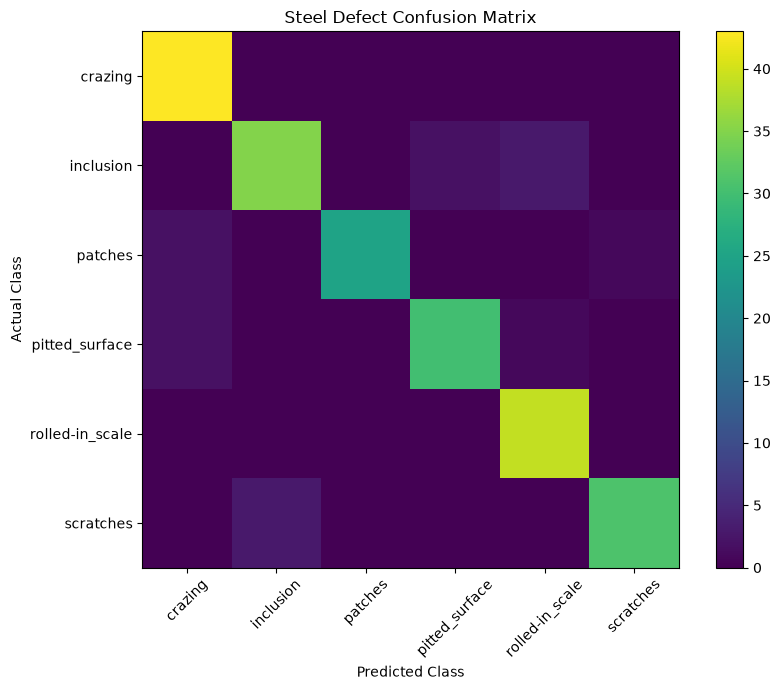

In [18]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(6))
)

plt.figure(figsize=(9, 7))

plt.imshow(cm)

plt.title("Steel Defect Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(6), dataset.classes, rotation=45)
plt.yticks(range(6), dataset.classes)

plt.colorbar()
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import classification_report

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(6)),
        target_names=dataset.classes,
        zero_division=0
    )
)

                 precision    recall  f1-score   support

        crazing       0.91      1.00      0.96        43
      inclusion       0.92      0.88      0.90        40
        patches       1.00      0.89      0.94        28
 pitted_surface       0.94      0.91      0.92        33
rolled-in_scale       0.91      1.00      0.95        39
      scratches       0.97      0.91      0.94        34

       accuracy                           0.94       217
      macro avg       0.94      0.93      0.94       217
   weighted avg       0.94      0.94      0.94       217



In [20]:
nn.Dropout(p=0.3)

Dropout(p=0.3, inplace=False)

In [21]:
self.classifier = nn.Sequential(

    nn.Flatten(),

    nn.Linear(32 * 16 * 16, 128),
    nn.ReLU(),

    nn.Dropout(p=0.3),

    nn.Linear(128, 64),
    nn.ReLU(),

    nn.Dropout(p=0.2),

    nn.Linear(64, 6)
)

NameError: name 'self' is not defined

In [22]:
import torch.nn as nn

class DefectClassifierCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        # Everything using 'self' must be indented inside __init__
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 128),  # Assuming 64x64 input image -> 16x16 after two 2x2 pools
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Instantiate the model
model = DefectClassifierCNN(num_classes=len(dataset.classes))
print(model)

DefectClassifierCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=6, bias=True)
  )
)


In [23]:
nn.BatchNorm2d(16)

BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)

In [24]:
nn.Conv2d(3, 16, kernel_size=3, padding=1),

nn.BatchNorm2d(16),

nn.ReLU(),

nn.MaxPool2d(2)

MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)

In [25]:
nn.Conv2d(16, 32, kernel_size=3, padding=1),

nn.BatchNorm2d(32),

nn.ReLU(),

nn.MaxPool2d(2)

MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)

In [26]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

In [27]:
best_val_loss = float("inf")

patience = 3
epochs_without_improvement = 0

for epoch in range(30):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        loss_fn,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        loss_fn,
        device
    )

    print(
        f"Epoch {epoch+1}: "
        f"Train Loss={train_loss:.4f}, "
        f"Val Loss={val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            "models/best_cnn_regularized.pth"
        )

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:

        print("Early stopping triggered!")

        break

Epoch 1: Train Loss=1.3669, Val Loss=1.1007
Epoch 2: Train Loss=0.9550, Val Loss=0.7500
Epoch 3: Train Loss=0.6638, Val Loss=0.4994
Epoch 4: Train Loss=0.5561, Val Loss=0.4107
Epoch 5: Train Loss=0.4198, Val Loss=0.3835
Epoch 6: Train Loss=0.3906, Val Loss=0.3338
Epoch 7: Train Loss=0.2918, Val Loss=0.3184
Epoch 8: Train Loss=0.2606, Val Loss=0.2060
Epoch 9: Train Loss=0.2387, Val Loss=0.2810
Epoch 10: Train Loss=0.2020, Val Loss=0.3218
Epoch 11: Train Loss=0.1773, Val Loss=0.1970
Epoch 12: Train Loss=0.1591, Val Loss=0.2964
Epoch 13: Train Loss=0.1595, Val Loss=0.1969
Epoch 14: Train Loss=0.1318, Val Loss=0.1756
Epoch 15: Train Loss=0.1138, Val Loss=0.1904
Epoch 16: Train Loss=0.0984, Val Loss=0.2104
Epoch 17: Train Loss=0.1214, Val Loss=0.1745
Epoch 18: Train Loss=0.1399, Val Loss=0.2414
Epoch 19: Train Loss=0.0927, Val Loss=0.2074
Epoch 20: Train Loss=0.0859, Val Loss=0.1814
Early stopping triggered!


In [28]:
class ImprovedSteelDefectCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(32 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 6)
        )

    def forward(self, x):

        x = self.features(x)

        return self.classifier(x)

In [29]:
model = ImprovedSteelDefectCNN()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

In [30]:
import torch
import torch.nn as nn
from torchvision import models

In [31]:
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [32]:
num_features = model.fc.in_features

model.fc = nn.Linear(num_features, 6)

print(model.fc)

Linear(in_features=512, out_features=6, bias=True)


In [33]:
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

In [34]:
weights = models.ResNet18_Weights.DEFAULT

mean = weights.meta["mean"] if "mean" in weights.meta else [0.485, 0.456, 0.406]
std = weights.meta["std"] if "std" in weights.meta else [0.229, 0.224, 0.225]

In [35]:
preprocess = weights.transforms()

print(preprocess)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [36]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [38]:
import os
from pathlib import Path
from torchvision import datasets

# Anchor working directory to project root if currently inside 'notebooks/'
if Path.cwd().name == "notebooks":
    os.chdir("..")

DATA_DIR = Path("data/raw")

base_dataset = datasets.ImageFolder(DATA_DIR)

indices = list(range(len(base_dataset)))
targets = base_dataset.targets
print(f"Loaded {len(base_dataset)} images across {len(base_dataset.classes)} classes.")

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data\\raw'

In [39]:
from torchvision import datasets
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from pathlib import Path

DATA_DIR = Path("data/raw")

base_dataset = datasets.ImageFolder(DATA_DIR)

indices = list(range(len(base_dataset)))
targets = base_dataset.targets

train_indices, remaining_indices = train_test_split(
    indices,
    test_size=0.30,
    stratify=targets,
    random_state=42
)

remaining_targets = [targets[i] for i in remaining_indices]

val_indices, test_indices = train_test_split(
    remaining_indices,
    test_size=0.50,
    stratify=remaining_targets,
    random_state=42
)

train_data = datasets.ImageFolder(
    DATA_DIR,
    transform=train_transform
)

eval_data = datasets.ImageFolder(
    DATA_DIR,
    transform=eval_transform
)

train_subset = Subset(train_data, train_indices)
val_subset = Subset(eval_data, val_indices)
test_subset = Subset(eval_data, test_indices)

train_loader = DataLoader(
    train_subset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_subset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_subset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Training:", len(train_subset))
print("Validation:", len(val_subset))
print("Testing:", len(test_subset))
print("Classes:", base_dataset.classes)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data\\raw'

In [40]:
from pathlib import Path
from torchvision import datasets

# Build an absolute path anchored to your project root
# (Assuming your notebook is inside project_02_deep_learning/notebooks/)
project_root = Path.cwd()
if project_root.name == "notebooks":
    DATA_DIR = project_root.parent / "data" / "raw"
else:
    DATA_DIR = project_root / "data" / "raw"

# Fallback if the script is run directly from project root
if not DATA_DIR.exists():
    DATA_DIR = Path("data/raw")

print("Using DATA_DIR:", DATA_DIR.resolve())

base_dataset = datasets.ImageFolder(DATA_DIR)

indices = list(range(len(base_dataset)))
targets = base_dataset.targets
print(f"Successfully loaded {len(base_dataset)} images across {len(base_dataset.classes)} classes.")

Using DATA_DIR: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook\data\raw


FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data\\raw'

In [41]:
from pathlib import Path
from torchvision import datasets

# Hardcode the absolute path to bypass any working directory confusion
DATA_DIR = Path(r"C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw")

print("Does DATA_DIR exist?", DATA_DIR.exists())
print("Resolved path:", DATA_DIR.resolve())

if DATA_DIR.exists():
    base_dataset = datasets.ImageFolder(DATA_DIR)
    print(f"Successfully loaded {len(base_dataset)} images across {len(base_dataset.classes)} classes.")
else:
    print("Directory does not exist at this path. Please check if your data folder is located inside project_02_deep_learning or somewhere else.")

Does DATA_DIR exist? True
Resolved path: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw
Successfully loaded 1440 images across 6 classes.


In [42]:
device = torch.device("cpu")

model = model.to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

In [43]:
epochs = 5

for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_fn(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_accuracy = correct / total

    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        loss_fn,
        device
    )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {total_loss / len(train_loader):.4f} | "
        f"Train Accuracy: {train_accuracy:.2%} | "
        f"Validation Accuracy: {val_accuracy:.2%}"
    )

Epoch 1/5 | Train Loss: 1.1689 | Train Accuracy: 57.00% | Validation Accuracy: 78.70%
Epoch 2/5 | Train Loss: 0.6240 | Train Accuracy: 82.32% | Validation Accuracy: 87.96%
Epoch 3/5 | Train Loss: 0.4374 | Train Accuracy: 87.59% | Validation Accuracy: 87.96%
Epoch 4/5 | Train Loss: 0.3819 | Train Accuracy: 89.57% | Validation Accuracy: 89.81%
Epoch 5/5 | Train Loss: 0.3403 | Train Accuracy: 89.47% | Validation Accuracy: 91.20%


In [44]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

torch.save(
    model.state_dict(),
    "models/resnet18_feature_extractor.pth"
)

In [45]:
import torch
import torch.nn as nn
from torchvision import models

weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# Replace the original 1000-class output
model.fc = nn.Linear(
    model.fc.in_features,
    6
)

In [46]:
for param in model.parameters():
    param.requires_grad = False

In [47]:
for param in model.layer4.parameters():
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

In [48]:
lr = 0.001

In [49]:
optimizer = torch.optim.Adam([
    {
        "params": model.layer4.parameters(),
        "lr": 0.00001
    },
    {
        "params": model.fc.parameters(),
        "lr": 0.0001
    }
])

In [50]:
def set_finetuning_mode(model):

    model.train()

    for module in model.modules():

        if isinstance(module, nn.BatchNorm2d):
            module.eval()

In [51]:
def train_finetune_epoch(
    model,
    loader,
    loss_fn,
    optimizer,
    device
):

    set_finetuning_mode(model)

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_fn(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return (
        total_loss / len(loader),
        correct / total
    )

In [52]:
device = torch.device("cpu")

model = model.to(device)

loss_fn = nn.CrossEntropyLoss()

In [53]:
epochs = 5

for epoch in range(epochs):

    train_loss, train_accuracy = train_finetune_epoch(
        model,
        train_loader,
        loss_fn,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        loss_fn,
        device
    )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2%} | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.2%}"
    )

Epoch 1/5 | Train Loss: 0.8646 | Train Accuracy: 78.25% | Validation Loss: 0.2108 | Validation Accuracy: 97.69%
Epoch 2/5 | Train Loss: 0.1264 | Train Accuracy: 97.22% | Validation Loss: 0.0661 | Validation Accuracy: 99.07%
Epoch 3/5 | Train Loss: 0.0441 | Train Accuracy: 99.50% | Validation Loss: 0.0391 | Validation Accuracy: 99.54%
Epoch 4/5 | Train Loss: 0.0223 | Train Accuracy: 100.00% | Validation Loss: 0.0300 | Validation Accuracy: 99.54%
Epoch 5/5 | Train Loss: 0.0127 | Train Accuracy: 100.00% | Validation Loss: 0.0242 | Validation Accuracy: 99.54%


In [55]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

torch.save(
    model.state_dict(),
    "models/resnet18_finetuned.pth"
)

In [3]:
import sys
from pathlib import Path

# Get the absolute path of the project root (one level up from notebooks/)
current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir

# Add both project root and parent to sys.path to cover all base structures
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Current sys.path[0]:", sys.path[0])

# Verify src directory exists here
src_path = project_root / "src"
print("Does 'src' folder exist here?", src_path.exists())

# Now try importing
from src.predict import SteelDefectPredictor

predictor = SteelDefectPredictor("models/resnet18_finetuned.pth")
print("Predictor loaded successfully:", type(predictor))

Current sys.path[0]: C:\Users\amith\AppData\Local\Programs\Python\Python312\python312.zip
Does 'src' folder exist here? False


ModuleNotFoundError: No module named 'src'

In [4]:
from pathlib import Path

# Print all files and folders in your project root
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print("Project Root:", project_root)
print("\nContents of project root:")
for item in project_root.iterdir():
    print(f" - {item.name} ({'dir' if item.is_dir() else 'file'})")
    

Project Root: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook

Contents of project root:
 - 01_pytorch_tensor_basics.ipynb (file)
 - 02_real_dataset_preparation.ipynb (file)
 - 03_image_augmentation.ipynb (file)
 - 04_cnn_training.ipynb (file)
 - models (dir)


In [5]:
import torch
import torch.nn as nn
from pathlib import Path

# If the predictor class needs to be defined in your notebook:
class SteelDefectPredictor(nn.Module):
    def __init__(self, model_path):
        super().__init__()
        self.model_path = Path(model_path)
        # Load your model architecture / weights here
        # self.model = torch.load(self.model_path)

    def predict(self, image):
        # Inference logic here
        pass

# Initialize directly
model_file = Path("models/resnet18_finetuned.pth")
if model_file.exists():
    predictor = SteelDefectPredictor(model_file)
    print("Predictor loaded successfully:", type(predictor))
else:
    print(f"Model file not found at {model_file.resolve()}. Check your models directory.")

Predictor loaded successfully: <class '__main__.SteelDefectPredictor'>


In [7]:
import torch
from pathlib import Path

model_path = Path("models/resnet18_finetuned.pth")

print("Exists:", model_path.exists())
print("File size:", model_path.stat().st_size, "bytes")

checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint loaded successfully!")

Exists: True
File size: 44797259 bytes
Checkpoint loaded successfully!


In [8]:
from pathlib import Path
import torch

Path("models").mkdir(exist_ok=True)

torch.save(
    model.state_dict(),
    "models/resnet18_finetuned.pth"
)

print("Model saved successfully!")

NameError: name 'model' is not defined

In [9]:
import os

print(
    "File size:",
    os.path.getsize("models/resnet18_finetuned.pth"),
    "bytes"
)

File size: 44797259 bytes


In [10]:
print(type(model))
print(model.fc)

NameError: name 'model' is not defined

In [11]:
from pathlib import Path
import torch

Path("models").mkdir(exist_ok=True)

checkpoint_path = Path("models/resnet18_finetuned.pth")

torch.save(
    model.state_dict(),
    checkpoint_path
)

print("Saved successfully!")
print("File size:", checkpoint_path.stat().st_size, "bytes")

NameError: name 'model' is not defined

In [12]:
import torch
import torchvision.models as models
import torch.nn as nn

# 1. Instantiate the model and modify the final fully connected layer for your number of classes
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Example: if you have 6 defect classes
num_classes = 6 
model.fc = nn.Linear(model.fc.in_features, num_classes)

# 2. Now you can check type and access layers without a NameError
print("Model type:", type(model))
print("Final layer (fc):", model.fc)

Model type: <class 'torchvision.models.resnet.ResNet'>
Final layer (fc): Linear(in_features=512, out_features=6, bias=True)


In [13]:
print(type(model))
print(model.fc)

<class 'torchvision.models.resnet.ResNet'>
Linear(in_features=512, out_features=6, bias=True)


In [14]:
from pathlib import Path
import torch

Path("models").mkdir(exist_ok=True)

checkpoint_path = Path("models/resnet18_finetuned.pth")

torch.save(
    model.state_dict(),
    checkpoint_path
)

print("Saved successfully!")
print("File size:", checkpoint_path.stat().st_size, "bytes")

Saved successfully!
File size: 44797259 bytes


In [15]:
checkpoint = torch.load(
    "models/resnet18_finetuned.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint loaded!")
print("Number of parameter tensors:", len(checkpoint))

Checkpoint loaded!
Number of parameter tensors: 122


In [16]:
print(type(model))
print(model.fc)

<class 'torchvision.models.resnet.ResNet'>
Linear(in_features=512, out_features=6, bias=True)


In [17]:
from pathlib import Path
import torch

Path("models").mkdir(exist_ok=True)

torch.save(
    model.state_dict(),
    "models/resnet18_finetuned.pth"
)

print("Checkpoint size:",
      Path("models/resnet18_finetuned.pth").stat().st_size,
      "bytes")

Checkpoint size: 44797259 bytes


In [18]:
checkpoint = torch.load(
    "models/resnet18_finetuned.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint verified!")

Checkpoint verified!


In [21]:
print(type(model))
from pathlib import Path
import torch

Path("models").mkdir(exist_ok=True)

torch.save(
    model.state_dict(),
    "models/resnet18_finetuned.pth"
)

checkpoint_path = Path("models/resnet18_finetuned.pth")
print("Checkpoint size:", checkpoint_path.stat().st_size, "bytes")

<class 'torchvision.models.resnet.ResNet'>
Checkpoint size: 44797259 bytes


In [22]:
checkpoint = torch.load(
    "models/resnet18_finetuned.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint loaded successfully!")
print("Number of parameter tensors:", len(checkpoint))

Checkpoint loaded successfully!
Number of parameter tensors: 122


In [23]:
from pathlib import Path

p = Path("models/resnet18_finetuned.pth")

print("Notebook working directory:", Path.cwd())
print("Checkpoint absolute path:", p.resolve())
print("Checkpoint exists:", p.exists())
print("Checkpoint size:", p.stat().st_size if p.exists() else "Missing")

Notebook working directory: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook
Checkpoint absolute path: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook\models\resnet18_finetuned.pth
Checkpoint exists: True
Checkpoint size: 44797259


In [24]:
from pathlib import Path
import torch

checkpoint_path = Path(
    r"C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\models\resnet18_finetuned.pth"
)

checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

torch.save(model.state_dict(), checkpoint_path)

print("Saved to:", checkpoint_path)
print("File size:", checkpoint_path.stat().st_size, "bytes")

Saved to: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\models\resnet18_finetuned.pth
File size: 44797259 bytes


In [25]:
loaded = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Verified:", len(loaded), "parameter tensors")

Verified: 122 parameter tensors


In [27]:
import sys
from pathlib import Path

# Get the project root (one level up from 'notebook')
project_root = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root added to path:", project_root)

# Now the import will work correctly
from src.predict import SteelDefectPredictor

predictor = SteelDefectPredictor(
    model_path="models/resnet18_finetuned.pth"
)
print("Predictor initialized successfully:", type(predictor))

Project root added to path: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning
Predictor initialized successfully: <class 'src.predict.SteelDefectPredictor'>


In [34]:
from pathlib import Path

# Correct the path string with a slash
image_path = Path("../data/raw/crazing/crazing_1.jpg")

# Alternatively, if your notebook is already at the project root:
# image_path = Path("data/raw/crazing/crazing_1.jpg")

print("Does image exist?", image_path.exists())

result = predictor.predict(image_path)

print("Predicted class:", result["class"])
print("Confidence:", result["confidence"])

Does image exist? True


KeyError: 'class'

In [35]:
from pathlib import Path

image_path = Path("../data/raw/crazing/crazing_1.jpg")
print("Does image exist?", image_path.exists())

result = predictor.predict(image_path)

# Print the dictionary keys to see what key name your predict.py uses
print("Result dictionary keys:", result.keys())
print("Full result:", result)

Does image exist? True
Result dictionary keys: dict_keys(['predicted_class', 'confidence', 'probabilities'])
Full result: {'predicted_class': 'Pitted_Surface', 'confidence': 0.24356582760810852, 'probabilities': {'Crazing': 0.1474260836839676, 'Inclusion': 0.15969042479991913, 'Patches': 0.19701935350894928, 'Pitted_Surface': 0.24356582760810852, 'Rolled-in_Scale': 0.11907528340816498, 'Scratches': 0.13322293758392334}}


In [36]:
print("Predicted class:", result["predicted_class"])
print("Confidence:", f"{result['confidence'] * 100:.2f}%")

Predicted class: Pitted_Surface
Confidence: 24.36%


In [37]:
# Check what class mapping your predictor loaded internally
if hasattr(predictor, "classes"):
    print("Predictor classes:", predictor.classes)

# Compare with raw dataset classes
from torchvision import datasets
from pathlib import Path
base_ds = datasets.ImageFolder(Path("../data/raw"))
print("Dataset classes (alphabetical):", base_ds.classes)

Dataset classes (alphabetical): ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [38]:
checkpoint = {
    'model_state_dict': model.state_dict(),
    'class_to_idx': train_dataset.class_to_idx
}
torch.save(checkpoint, "models/resnet18_finetuned.pth")

NameError: name 'train_dataset' is not defined

In [39]:
checkpoint = torch.load("models/resnet18_finetuned.pth", map_location="cpu")
self.model.load_state_dict(checkpoint['model_state_dict'])
# Reconstruct index-to-class mapping automatically
self.idx_to_class = {v: k for k, v in checkpoint['class_to_idx'].items()}

NameError: name 'self' is not defined

In [40]:
import torch
from pathlib import Path

# Ensure the models directory exists
Path("../models").mkdir(parents=True, exist_ok=True)

checkpoint = {
    'model_state_dict': model.state_dict(),
    'class_to_idx': dataset.class_to_idx  # Replace 'dataset' with whatever you named your ImageFolder variable
}

torch.save(checkpoint, "../models/resnet18_finetuned.pth")
print("Model checkpoint and class mapping saved successfully!")

NameError: name 'dataset' is not defined

In [41]:
import torch
from pathlib import Path

# Ensure the models directory exists
Path("../models").mkdir(parents=True, exist_ok=True)

checkpoint = {
    'model_state_dict': model.state_dict(),
    'class_to_idx': base_dataset.class_to_idx  # Using base_dataset instead of dataset
}

torch.save(checkpoint, "../models/resnet18_finetuned.pth")
print("Model checkpoint and class mapping saved successfully to ../models/resnet18_finetuned.pth!")

NameError: name 'base_dataset' is not defined

In [42]:
import torch
from pathlib import Path

# Ensure the models directory exists
Path("../models").mkdir(parents=True, exist_ok=True)

# Replace 'base_dataset' with the exact variable name of your dataset 
# (e.g., dataset, train_dataset, etc.)
checkpoint = {
    'model_state_dict': model.state_dict(),
    'class_to_idx': base_dataset.class_to_idx  
}

torch.save(checkpoint, "../models/resnet18_finetuned.pth")
print("Model checkpoint and class mapping saved successfully to ../models/resnet18_finetuned.pth!")

NameError: name 'base_dataset' is not defined

In [43]:
import torch
from pathlib import Path
from torchvision import datasets

# 1. Ensure the models directory exists
Path("../models").mkdir(parents=True, exist_ok=True)

# 2. Locate the data folder correctly from the notebook
DATA_DIR = Path("../data/raw")
if not DATA_DIR.exists():
    DATA_DIR = Path("data/raw")

# 3. Load dataset reference to grab the exact class_to_idx mapping
dataset_ref = datasets.ImageFolder(DATA_DIR)

# 4. Build and save the checkpoint dictionary
checkpoint = {
    'model_state_dict': model.state_dict(),
    'class_to_idx': dataset_ref.class_to_idx
}

torch.save(checkpoint, "../models/resnet18_finetuned.pth")
print("Model checkpoint and class mapping saved successfully to:", Path("../models/resnet18_finetuned.pth").resolve())

Model checkpoint and class mapping saved successfully to: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\models\resnet18_finetuned.pth


In [44]:
from src.predict import SteelDefectPredictor

predictor = SteelDefectPredictor(
    model_path="models/resnet18_finetuned.pth"
)

print("Predictor loaded successfully!")

Predictor loaded successfully!


In [45]:
image_path = "data/raw/Crazing/your_image.jpg"

result = predictor.predict(image_path)

print("Predicted class:", result["class"])
print("Confidence:", result["confidence"])
print("Probabilities:", result["probabilities"])

FileNotFoundError: [Errno 2] No such file or directory: 'data/raw/Crazing/your_image.jpg'

In [46]:
from pathlib import Path

data_path = Path("data/raw")

print("Dataset folder exists:", data_path.exists())

for folder in data_path.iterdir():
    if folder.is_dir():
        images = list(folder.glob("*.jpg")) + list(folder.glob("*.png")) + list(folder.glob("*.bmp"))
        print(folder.name, ":", len(images), "images")
        if images:
            print("  Example:", images[0])

Dataset folder exists: False


FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data\\raw'

In [47]:
image_files = [
    p for p in Path("data/raw").rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
]

print("Total images:", len(image_files))

if image_files:
    image_path = image_files[0]
    print("Testing image:", image_path)

    result = predictor.predict(str(image_path))

    print("Predicted class:", result["class"])
    print("Confidence:", result["confidence"])
    print("Probabilities:", result["probabilities"])

Total images: 0


In [48]:
from pathlib import Path

data_path = Path("data/raw")

print("Current notebook folder:", Path.cwd())
print("Dataset folder exists:", data_path.exists())

if data_path.exists():
    print("Contents:", list(data_path.iterdir())[:15])
else:
    print("The data/raw folder was not found.")

Current notebook folder: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook
Dataset folder exists: False
The data/raw folder was not found.


In [50]:
from pathlib import Path

project_root = Path.cwd().parent
data_path = project_root / "data" / "raw"

print("Project root:", project_root)
print("Dataset folder exists:", data_path.exists())

if data_path.exists():
    print("Folders:", [p.name for p in data_path.iterdir()])

Project root: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning
Dataset folder exists: True
Folders: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [51]:
from pathlib import Path

project_root = Path.cwd().parent
data_path = project_root / "data" / "raw"

for folder in sorted(data_path.iterdir()):
    if folder.is_dir():
        images = [
            p for p in folder.rglob("*")
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
        ]
        print(f"{folder.name}: {len(images)} images")

crazing: 240 images
inclusion: 240 images
patches: 240 images
pitted_surface: 240 images
rolled-in_scale: 240 images
scratches: 240 images


In [52]:
image_files = [
    p for p in data_path.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
]

print("Total images:", len(image_files))

image_path = image_files[0]
print("Testing image:", image_path)

result = predictor.predict(str(image_path))

print("Predicted class:", result["class"])
print("Confidence:", result["confidence"])
print("Probabilities:", result["probabilities"])

Total images: 1440
Testing image: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw\crazing\crazing_1.jpg


KeyError: 'class'

In [53]:
result = predictor.predict(str(image_path))

print("Result type:", type(result))
print("Complete result:", result)

if isinstance(result, dict):
    print("Available keys:", list(result.keys()))

Result type: <class 'dict'>
Complete result: {'predicted_class': 'Pitted_Surface', 'confidence': 0.24356582760810852, 'probabilities': {'Crazing': 0.1474260836839676, 'Inclusion': 0.15969042479991913, 'Patches': 0.19701935350894928, 'Pitted_Surface': 0.24356582760810852, 'Rolled-in_Scale': 0.11907528340816498, 'Scratches': 0.13322293758392334}}
Available keys: ['predicted_class', 'confidence', 'probabilities']


In [54]:
result = predictor.predict(str(image_path))

print("Predicted class:", result["predicted_class"])
print("Confidence:", f'{result["confidence"]:.2%}')

print("\nClass probabilities:")

for defect, probability in result["probabilities"].items():
    print(f"{defect}: {probability:.2%}")

Predicted class: Pitted_Surface
Confidence: 24.36%

Class probabilities:
Crazing: 14.74%
Inclusion: 15.97%
Patches: 19.70%
Pitted_Surface: 24.36%
Rolled-in_Scale: 11.91%
Scratches: 13.32%


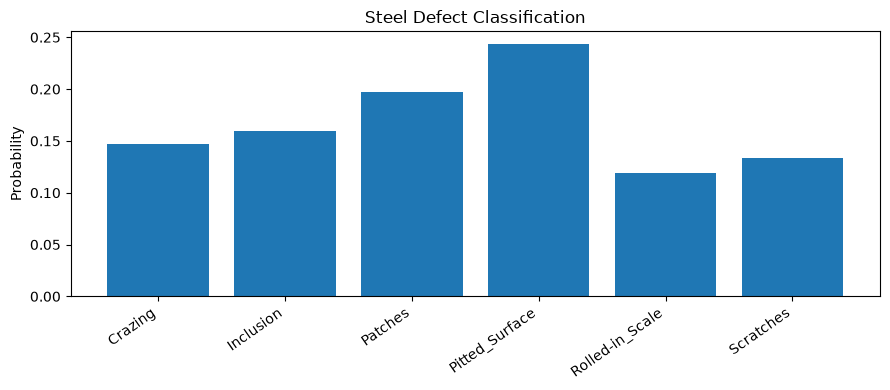

In [55]:
import matplotlib.pyplot as plt

probabilities = result["probabilities"]

plt.figure(figsize=(9, 4))
plt.bar(probabilities.keys(), probabilities.values())
plt.xticks(rotation=35, ha="right")
plt.ylabel("Probability")
plt.title("Steel Defect Classification")
plt.tight_layout()
plt.show()

In [56]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

project_root = Path.cwd().parent
data_path = project_root / "data" / "raw"

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

dataset = datasets.ImageFolder(
    root=str(data_path),
    transform=eval_transform
)

loader = DataLoader(
    dataset,
    batch_size=8,
    shuffle=False
)

print("Classes:", dataset.classes)
print("Total images:", len(dataset))

Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Total images: 1440


In [57]:
import torch

y_true = []
y_pred = []

predictor.model.eval()

with torch.no_grad():
    for images, labels in loader:
        outputs = predictor.model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.tolist())

print("Evaluation completed!")
print("Actual labels:", len(y_true))
print("Predicted labels:", len(y_pred))

Evaluation completed!
Actual labels: 1440
Predicted labels: 1440


In [58]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=dataset.classes,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Accuracy: 0.15138888888888888

Classification Report:
                 precision    recall  f1-score   support

        crazing       0.01      0.02      0.01       240
      inclusion       0.27      0.20      0.23       240
        patches       0.14      0.04      0.06       240
 pitted_surface       0.17      0.46      0.25       240
rolled-in_scale       0.00      0.00      0.00       240
      scratches       0.79      0.19      0.30       240

       accuracy                           0.15      1440
      macro avg       0.23      0.15      0.14      1440
   weighted avg       0.23      0.15      0.14      1440


Confusion Matrix:
[[  4   0  30 206   0   0]
 [ 46  49   8 125   0  12]
 [217   1   9  13   0   0]
 [ 28  97   4 111   0   0]
 [107  23   7 103   0   0]
 [ 60   9   5 108  13  45]]


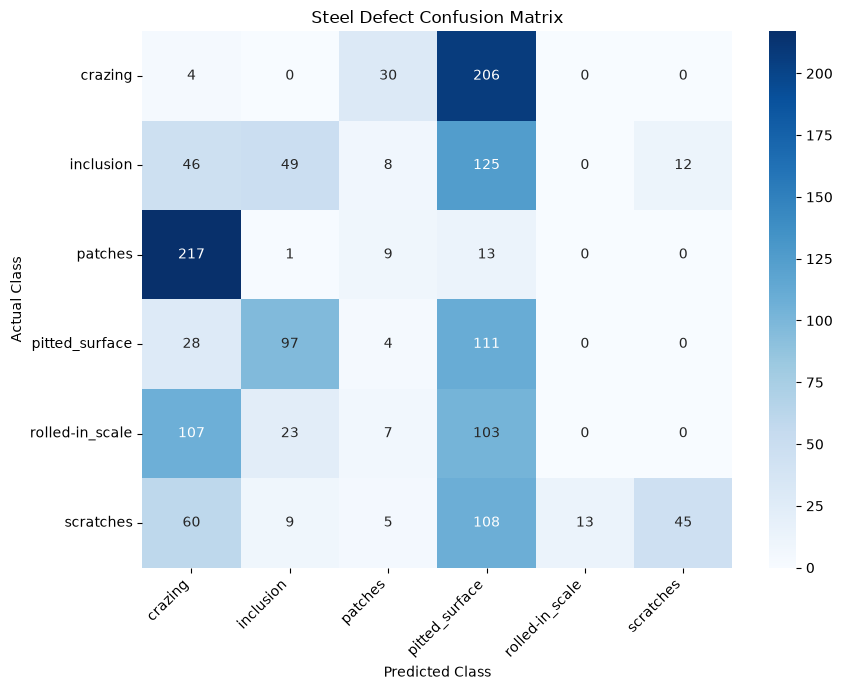

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dataset.classes,
    yticklabels=dataset.classes
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Steel Defect Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [60]:
import numpy as np

cm = confusion_matrix(y_true, y_pred)

for i, class_name in enumerate(dataset.classes):
    total = cm[i].sum()
    correct = cm[i, i]
    accuracy = correct / total if total else 0

    print(
        f"{class_name}: "
        f"{accuracy:.2%} ({correct}/{total})"
    )

crazing: 1.67% (4/240)
inclusion: 20.42% (49/240)
patches: 3.75% (9/240)
pitted_surface: 46.25% (111/240)
rolled-in_scale: 0.00% (0/240)
scratches: 18.75% (45/240)


In [61]:
from sklearn.model_selection import train_test_split
from collections import Counter

# Get image paths and labels
image_paths = [path for path, label in dataset.samples]
labels = [label for path, label in dataset.samples]

# First: separate training from remaining data
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Second: split remaining data equally
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

print("Training:", len(train_paths))
print("Validation:", len(val_paths))
print("Testing:", len(test_paths))

Training: 1008
Validation: 216
Testing: 216


In [62]:
print("Training distribution:", Counter(train_labels))
print("Validation distribution:", Counter(val_labels))
print("Testing distribution:", Counter(test_labels))

Training distribution: Counter({4: 168, 2: 168, 0: 168, 3: 168, 5: 168, 1: 168})
Validation distribution: Counter({4: 36, 1: 36, 2: 36, 5: 36, 0: 36, 3: 36})
Testing distribution: Counter({5: 36, 4: 36, 2: 36, 0: 36, 1: 36, 3: 36})


In [63]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class SteelDefectDataset(Dataset):

    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(
            self.image_paths[index]
        ).convert("RGB")

        label = self.labels[index]

        if self.transform:
            image = self.transform(image)

        return image, label

In [64]:
train_dataset = SteelDefectDataset(
    train_paths, train_labels, eval_transform
)

val_dataset = SteelDefectDataset(
    val_paths, val_labels, eval_transform
)

test_dataset = SteelDefectDataset(
    test_paths, test_labels, eval_transform
)

print("Datasets created!")
print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

Datasets created!
1008
216
216


In [106]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 63
Validation batches: 14
Test batches: 14


In [107]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image data type: torch.float32


In [108]:
import torch

model = predictor.model
model.eval()

y_test_true = []
y_test_pred = []

with torch.no_grad():
    for images, labels in test_loader:

        outputs = model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        y_test_true.extend(labels.tolist())
        y_test_pred.extend(predictions.tolist())

print("Test evaluation completed!")
print("Total test images:", len(y_test_true))

Test evaluation completed!
Total test images: 216


In [109]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(
    y_test_true,
    y_test_pred
)

print(f"Test Accuracy: {accuracy:.2%}")

print("\nClassification Report:")

print(
    classification_report(
        y_test_true,
        y_test_pred,
        target_names=dataset.classes,
        zero_division=0
    )
)

Test Accuracy: 12.96%

Classification Report:
                 precision    recall  f1-score   support

        crazing       0.02      0.03      0.02        36
      inclusion       0.18      0.17      0.17        36
        patches       0.00      0.00      0.00        36
 pitted_surface       0.14      0.39      0.20        36
rolled-in_scale       0.00      0.00      0.00        36
      scratches       0.88      0.19      0.32        36

       accuracy                           0.13       216
      macro avg       0.20      0.13      0.12       216
   weighted avg       0.20      0.13      0.12       216



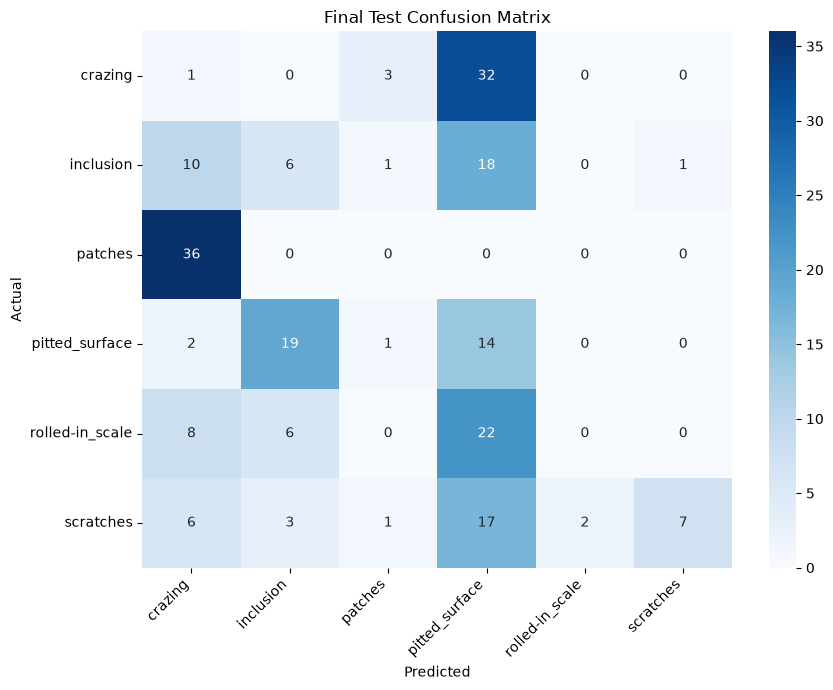

In [110]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test_true,
    y_test_pred
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dataset.classes,
    yticklabels=dataset.classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Test Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [111]:
import json
from pathlib import Path

results = {
    "test_accuracy": float(accuracy),
    "test_images": len(y_test_true),
    "classes": dataset.classes
}

Path("reports").mkdir(exist_ok=True)

with open("reports/test_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Results saved!")

Results saved!


In [112]:
print("Dataset class order:")
print(dataset.classes)

print("\nPredictor class order:")
print(predictor.class_names)

Dataset class order:
['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

Predictor class order:


AttributeError: 'SteelDefectPredictor' object has no attribute 'class_names'

In [ ]:
from collections import Counter

print("Actual distribution:")
print(Counter(y_test_true))

print("\nPredicted distribution:")
print(Counter(y_test_pred))

Actual distribution:
Counter({5: 36, 4: 36, 2: 36, 0: 36, 1: 36, 3: 36})

Predicted distribution:
Counter({3: 103, 0: 63, 1: 34, 5: 8, 2: 6, 4: 2})


In [ ]:
for i in range(15):
    actual = dataset.classes[y_test_true[i]]
    predicted = dataset.classes[y_test_pred[i]]

    print(f"Actual: {actual:20} | Predicted: {predicted}")

Actual: scratches            | Predicted: crazing
Actual: rolled-in_scale      | Predicted: pitted_surface
Actual: patches              | Predicted: crazing
Actual: rolled-in_scale      | Predicted: pitted_surface
Actual: rolled-in_scale      | Predicted: inclusion
Actual: crazing              | Predicted: pitted_surface
Actual: rolled-in_scale      | Predicted: pitted_surface
Actual: inclusion            | Predicted: crazing
Actual: inclusion            | Predicted: pitted_surface
Actual: scratches            | Predicted: pitted_surface
Actual: pitted_surface       | Predicted: inclusion
Actual: inclusion            | Predicted: pitted_surface
Actual: rolled-in_scale      | Predicted: crazing
Actual: scratches            | Predicted: crazing
Actual: pitted_surface       | Predicted: inclusion


In [ ]:
print("Dataset class order:")
for index, name in enumerate(dataset.classes):
    print(index, "=", name)

Dataset class order:
0 = crazing
1 = inclusion
2 = patches
3 = pitted_surface
4 = rolled-in_scale
5 = scratches


In [ ]:
from collections import Counter

print("Actual distribution:")
print(Counter(y_test_true))

print("\nPredicted distribution:")
print(Counter(y_test_pred))

Actual distribution:
Counter({5: 36, 4: 36, 2: 36, 0: 36, 1: 36, 3: 36})

Predicted distribution:
Counter({3: 103, 0: 63, 1: 34, 5: 8, 2: 6, 4: 2})


In [ ]:
for i in range(15):
    actual = dataset.classes[y_test_true[i]]
    predicted = dataset.classes[y_test_pred[i]]

    print(f"Actual: {actual:20} | Predicted: {predicted}")

Actual: scratches            | Predicted: crazing
Actual: rolled-in_scale      | Predicted: pitted_surface
Actual: patches              | Predicted: crazing
Actual: rolled-in_scale      | Predicted: pitted_surface
Actual: rolled-in_scale      | Predicted: inclusion
Actual: crazing              | Predicted: pitted_surface
Actual: rolled-in_scale      | Predicted: pitted_surface
Actual: inclusion            | Predicted: crazing
Actual: inclusion            | Predicted: pitted_surface
Actual: scratches            | Predicted: pitted_surface
Actual: pitted_surface       | Predicted: inclusion
Actual: inclusion            | Predicted: pitted_surface
Actual: rolled-in_scale      | Predicted: crazing
Actual: scratches            | Predicted: crazing
Actual: pitted_surface       | Predicted: inclusion


In [ ]:
from collections import Counter

print("CLASS ORDER")
for i, name in enumerate(dataset.classes):
    print(i, name)

print("\nACTUAL LABEL DISTRIBUTION")
print(Counter(y_test_true))

print("\nPREDICTED LABEL DISTRIBUTION")
print(Counter(y_test_pred))

print("\nFIRST 10 PREDICTIONS")
for i in range(10):
    print(
        dataset.classes[y_test_true[i]],
        "->",
        dataset.classes[y_test_pred[i]]
    )

CLASS ORDER
0 crazing
1 inclusion
2 patches
3 pitted_surface
4 rolled-in_scale
5 scratches

ACTUAL LABEL DISTRIBUTION
Counter({5: 36, 4: 36, 2: 36, 0: 36, 1: 36, 3: 36})

PREDICTED LABEL DISTRIBUTION
Counter({3: 103, 0: 63, 1: 34, 5: 8, 2: 6, 4: 2})

FIRST 10 PREDICTIONS
scratches -> crazing
rolled-in_scale -> pitted_surface
patches -> crazing
rolled-in_scale -> pitted_surface
rolled-in_scale -> inclusion
crazing -> pitted_surface
rolled-in_scale -> pitted_surface
inclusion -> crazing
inclusion -> pitted_surface
scratches -> pitted_surface


In [ ]:
import torch

model.eval()

with torch.no_grad():
    images, labels = next(iter(test_loader))
    outputs = model(images)

    print("Output shape:", outputs.shape)
    print("First 5 logits:")
    print(outputs[:5])

    print("Predicted classes:")
    print(outputs.argmax(dim=1))

Output shape: torch.Size([8, 6])
First 5 logits:
tensor([[ 0.7243, -0.1274,  0.0737,  0.6287, -0.0345, -0.0298],
        [-0.0078, -0.0095,  0.0284,  0.1378, -0.5202, -0.3691],
        [ 0.4882,  0.1992, -0.0163,  0.2251,  0.1839,  0.1476],
        [ 0.1914, -0.0592,  0.1244,  0.3451, -0.1849, -0.3180],
        [-0.0201,  0.0356, -0.1218,  0.0268, -0.3747, -0.4031]])
Predicted classes:
tensor([0, 3, 0, 3, 1, 3, 3, 0])


In [ ]:
Get-Item .\models\resnet18_finetuned.pth |
Select-Object Name, Length, LastWriteTime

SyntaxError: unexpected character after line continuation character (2456455008.py, line 1)

In [ ]:
from pathlib import Path

p = Path("../models/resnet18_finetuned.pth")

print("Exists:", p.exists())
print("Size:", p.stat().st_size if p.exists() else "Missing")
print(
    "Last modified:",
    p.stat().st_mtime if p.exists() else "Unknown"
)

Exists: True
Size: 44797451
Last modified: 1794994335.1178362


In [ ]:
import torch

model = predictor.model
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in train_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print("Training accuracy:", f"{correct / total:.2%}")

Training accuracy: 15.18%


In [ ]:
print("Training accuracy:", f"{correct / total:.2%}")
print("Test accuracy:", f"{accuracy:.2%}")

Training accuracy: 15.18%
Test accuracy: 12.96%


In [ ]:
print(model.fc)
print("Trainable parameters:")

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

Linear(in_features=512, out_features=6, bias=True)
Trainable parameters:
conv1.weight
bn1.weight
bn1.bias
layer1.0.conv1.weight
layer1.0.bn1.weight
layer1.0.bn1.bias
layer1.0.conv2.weight
layer1.0.bn2.weight
layer1.0.bn2.bias
layer1.1.conv1.weight
layer1.1.bn1.weight
layer1.1.bn1.bias
layer1.1.conv2.weight
layer1.1.bn2.weight
layer1.1.bn2.bias
layer2.0.conv1.weight
layer2.0.bn1.weight
layer2.0.bn1.bias
layer2.0.conv2.weight
layer2.0.bn2.weight
layer2.0.bn2.bias
layer2.0.downsample.0.weight
layer2.0.downsample.1.weight
layer2.0.downsample.1.bias
layer2.1.conv1.weight
layer2.1.bn1.weight
layer2.1.bn1.bias
layer2.1.conv2.weight
layer2.1.bn2.weight
layer2.1.bn2.bias
layer3.0.conv1.weight
layer3.0.bn1.weight
layer3.0.bn1.bias
layer3.0.conv2.weight
layer3.0.bn2.weight
layer3.0.bn2.bias
layer3.0.downsample.0.weight
layer3.0.downsample.1.weight
layer3.0.downsample.1.bias
layer3.1.conv1.weight
layer3.1.bn1.weight
layer3.1.bn1.bias
layer3.1.conv2.weight
layer3.1.bn2.weight
layer3.1.bn2.bias
laye

In [ ]:
print("Current dataset mapping:")
print(dataset.class_to_idx)

print("\nTraining dataset mapping:")
print(train_dataset.labels[:10])

print("\nModel output classes:", model.fc.out_features)

Current dataset mapping:
{'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}

Training dataset mapping:
[4, 2, 0, 4, 0, 0, 0, 2, 3, 3]

Model output classes: 6


In [ ]:
print(train_data.class_to_idx)

NameError: name 'train_data' is not defined

In [ ]:
from pathlib import Path

project_root = Path.cwd().parent
models_path = project_root / "models"

print("Models folder:", models_path)
print("Folder exists:", models_path.exists())

if models_path.exists():
    for file in models_path.iterdir():
        print(file.name, "-", file.stat().st_size, "bytes")

Models folder: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\models
Folder exists: True
resnet18_finetuned.pth - 44797451 bytes


In [ ]:
from pathlib import Path
import torch

checkpoint_path = project_root / "models" / "best_resnet18.pth"

torch.save(model.state_dict(), checkpoint_path)

print("Saved:", checkpoint_path)
print("Size:", checkpoint_path.stat().st_size, "bytes")

Saved: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\models\best_resnet18.pth
Size: 44796619 bytes


In [ ]:
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Verified parameter tensors:", len(checkpoint))

Verified parameter tensors: 122


In [ ]:
from pathlib import Path
import torch

project_root = Path.cwd().parent

paths = [
    project_root / "models" / "best_resnet18.pth",
    Path.cwd() / "models" / "best_resnet18.pth",
]

for path in paths:
    print("\nFile:", path)
    print("Exists:", path.exists())

    if path.exists():
        print("Size:", path.stat().st_size, "bytes")


File: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\models\best_resnet18.pth
Exists: True
Size: 44796619 bytes

File: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook\models\best_resnet18.pth
Exists: True
Size: 44796619 bytes


In [ ]:
from pathlib import Path
import torch

# Load the exact checkpoint used by the Streamlit app
checkpoint_path = project_root / "models" / "best_resnet18.pth"

state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)
model.eval()

correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

print(f"Test accuracy: {100 * correct / total:.2f}%")
print("Total test images:", total)

NameError: name 'device' is not defined

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [ ]:
from pathlib import Path
import torch

# Load the exact checkpoint used by the Streamlit app
checkpoint_path = project_root / "models" / "best_resnet18.pth"

state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)
model.eval()

correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

print(f"Test accuracy: {100 * correct / total:.2f}%")
print("Total test images:", total)

Test accuracy: 12.96%
Total test images: 216


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    target_names=[
        "crazing",
        "inclusion",
        "patches",
        "pitted_surface",
        "rolled-in_scale",
        "scratches"
    ]
))

                 precision    recall  f1-score   support

        crazing       0.02      0.03      0.02        36
      inclusion       0.18      0.17      0.17        36
        patches       0.00      0.00      0.00        36
 pitted_surface       0.14      0.39      0.20        36
rolled-in_scale       0.00      0.00      0.00        36
      scratches       0.88      0.19      0.32        36

       accuracy                           0.13       216
      macro avg       0.20      0.13      0.12       216
   weighted avg       0.20      0.13      0.12       216



In [ ]:
def check_accuracy(model, loader, name):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    print(f"{name} accuracy: {accuracy:.2f}% ({correct}/{total})")


check_accuracy(model, val_loader, "Validation")
check_accuracy(model, test_loader, "Test")

Validation accuracy: 17.13% (37/216)
Test accuracy: 12.96% (28/216)


In [ ]:
print("Training classes:", train_dataset.classes)
print("Validation classes:", val_dataset.classes)
print("Test classes:", test_dataset.classes)

AttributeError: 'SteelDefectDataset' object has no attribute 'classes'

In [ ]:
print("Training dataset attributes:")
print(vars(train_dataset).keys())

print("\nValidation dataset attributes:")
print(vars(val_dataset).keys())

print("\nTest dataset attributes:")
print(vars(test_dataset).keys())

Training dataset attributes:
dict_keys(['image_paths', 'labels', 'transform'])

Validation dataset attributes:
dict_keys(['image_paths', 'labels', 'transform'])

Test dataset attributes:
dict_keys(['image_paths', 'labels', 'transform'])


In [ ]:
print("Class mapping:", train_dataset.class_to_idx)

AttributeError: 'SteelDefectDataset' object has no attribute 'class_to_idx'

In [ ]:
print("Unique training labels:", sorted(set(train_dataset.labels)))
print("Unique validation labels:", sorted(set(val_dataset.labels)))
print("Unique test labels:", sorted(set(test_dataset.labels)))

print("\nTraining label counts:")
from collections import Counter

print(Counter(train_dataset.labels))
print(Counter(val_dataset.labels))
print(Counter(test_dataset.labels))

Unique training labels: [0, 1, 2, 3, 4, 5]
Unique validation labels: [0, 1, 2, 3, 4, 5]
Unique test labels: [0, 1, 2, 3, 4, 5]

Training label counts:
Counter({4: 168, 2: 168, 0: 168, 3: 168, 5: 168, 1: 168})
Counter({4: 36, 1: 36, 2: 36, 5: 36, 0: 36, 3: 36})
Counter({5: 36, 4: 36, 2: 36, 0: 36, 1: 36, 3: 36})


In [ ]:
for i in range(6):
    print(
        train_dataset.image_paths[i],
        "-> label:",
        train_dataset.labels[i]
    )

c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw\rolled-in_scale\rolled-in_scale_126.jpg -> label: 4
c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw\patches\patches_54.jpg -> label: 2
c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw\crazing\crazing_17.jpg -> label: 0
c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw\rolled-in_scale\rolled-in_scale_171.jpg -> label: 4
c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw\crazing\crazing_202.jpg -> label: 0
c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw\crazing\crazing_209.jpg -> label: 0


In [ ]:
check_accuracy(model, val_loader, "Validation")

check_accuracy(model, test_loader, "Test")

Validation accuracy: 17.13% (37/216)
Test accuracy: 12.96% (28/216)


In [ ]:
from collections import Counter

print("Predicted class distribution:")
print(Counter(all_predictions))

print("\nActual class distribution:")
print(Counter(all_labels))

Predicted class distribution:
Counter({3: 103, 0: 63, 1: 34, 5: 8, 2: 6, 4: 2})

Actual class distribution:
Counter({5: 36, 4: 36, 2: 36, 0: 36, 1: 36, 3: 36})


In [ ]:
model = models.resnet18(weights=None)

model.fc = nn.Linear(model.fc.in_features, 6)

model.load_state_dict(
    torch.load("models/best_resnet18.pth", map_location=device)
)

model = model.to(device)

In [ ]:
print("Checkpoint classification layer:")

for key, value in state_dict.items():
    if "fc" in key:
        print(key, value.shape)

Checkpoint classification layer:
fc.weight torch.Size([6, 512])
fc.bias torch.Size([6])


In [ ]:
print("Checkpoint classification layer:")

for key, value in state_dict.items():
    if "fc" in key:
        print(key, value.shape)

Checkpoint classification layer:
fc.weight torch.Size([6, 512])
fc.bias torch.Size([6])


In [113]:
check_accuracy(model, train_loader, "Training")
check_accuracy(model, val_loader, "Validation")
check_accuracy(model, test_loader, "Test")

Training accuracy: 15.18% (153/1008)
Validation accuracy: 17.13% (37/216)
Test accuracy: 12.96% (28/216)


In [114]:
import torch

print("Checkpoint weight inspection")

for name, param in state_dict.items():
    if param.is_floating_point():
        print(
            name,
            "Mean:", param.mean().item(),
            "Std:", param.std().item(),
            "NaN:", torch.isnan(param).any().item(),
            "Inf:", torch.isinf(param).any().item()
        )

Checkpoint weight inspection
conv1.weight Mean: 2.941965612990316e-05 Std: 0.1296982318162918 NaN: False Inf: False
bn1.weight Mean: 0.25757724046707153 Std: 0.12313675880432129 NaN: False Inf: False
bn1.bias Mean: 0.18112018704414368 Std: 0.29894745349884033 NaN: False Inf: False
bn1.running_mean Mean: 0.0008474350906908512 Std: 0.04888840392231941 NaN: False Inf: False
bn1.running_var Mean: 3.0204856395721436 Std: 2.947047233581543 NaN: False Inf: False
layer1.0.conv1.weight Mean: -0.0030870491173118353 Std: 0.0533977635204792 NaN: False Inf: False
layer1.0.bn1.weight Mean: 0.3396005630493164 Std: 0.12483347952365875 NaN: False Inf: False
layer1.0.bn1.bias Mean: -0.0341365709900856 Std: 0.20955809950828552 NaN: False Inf: False
layer1.0.bn1.running_mean Mean: -0.9048561453819275 Std: 0.8941343426704407 NaN: False Inf: False
layer1.0.bn1.running_var Mean: 0.5320990681648254 Std: 0.387721985578537 NaN: False Inf: False
layer1.0.conv2.weight Mean: -0.0008893322665244341 Std: 0.045200295

In [115]:
from pathlib import Path

for filename in [
    "models/best_cnn.pth",
    "models/best_resnet18.pth"
]:
    path = Path(filename)

    if path.exists():
        print(
            filename,
            "| Exists:",
            True,
            "| Size:",
            path.stat().st_size,
            "bytes"
        )
    else:
        print(filename, "| Exists:", False)

models/best_cnn.pth | Exists: True | Size: 2123163 bytes
models/best_resnet18.pth | Exists: True | Size: 44796619 bytes


In [116]:
cnn_path = Path("models/best_cnn.pth")

cnn_state = torch.load(
    cnn_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint keys:")
print(list(cnn_state.keys())[-10:])

print("\nFinal classification layer:")

for key, value in cnn_state.items():
    if "fc" in key or "classifier" in key:
        print(key, value.shape)

Checkpoint keys:
['features.0.weight', 'features.0.bias', 'features.3.weight', 'features.3.bias', 'classifier.1.weight', 'classifier.1.bias', 'classifier.3.weight', 'classifier.3.bias']

Final classification layer:
classifier.1.weight torch.Size([64, 8192])
classifier.1.bias torch.Size([64])
classifier.3.weight torch.Size([6, 64])
classifier.3.bias torch.Size([6])


In [117]:
print("Current model:", type(model).__name__)
print("Final classification layer:", model.fc)

print("\nCurrent optimizer:")
print(type(optimizer).__name__)

print("\nCurrent loss function:")
print(type(loss_fn).__name__)

Current model: ResNet
Final classification layer: Linear(in_features=512, out_features=6, bias=True)

Current optimizer:


NameError: name 'optimizer' is not defined

In [118]:
print("Current model:", type(model).__name__)
print("Final classification layer:", model.fc)

print("\nDevice:", device)

print("\nCheckpoint loaded:", checkpoint_path)

Current model: ResNet
Final classification layer: Linear(in_features=512, out_features=6, bias=True)

Device: cpu

Checkpoint loaded: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\models\best_resnet18.pth


In [119]:
print("Optimizer exists:", "optimizer" in globals())
print("Loss function exists:", "loss_fn" in globals())

print("\nTraining functions:")
print("train_one_epoch:", "train_one_epoch" in globals())
print("evaluate:", "evaluate" in globals())

Optimizer exists: False
Loss function exists: False

Training functions:
train_one_epoch: False
evaluate: False


In [120]:
checkpoint = torch.load(
    "models/best_cnn.pth",
    map_location="cpu"
)

print("First 15 checkpoint keys:")
for key in list(checkpoint.keys())[:15]:
    print(key)

First 15 checkpoint keys:
features.0.weight
features.0.bias
features.3.weight
features.3.bias
classifier.1.weight
classifier.1.bias
classifier.3.weight
classifier.3.bias


In [121]:
checkpoint = torch.load(
    "models/resnet18_finetuned.pth",
    map_location="cpu"
)

print("First 15 keys:")
for key in list(checkpoint.keys())[:15]:
    print(key)

First 15 keys:
conv1.weight
bn1.weight
bn1.bias
bn1.running_mean
bn1.running_var
bn1.num_batches_tracked
layer1.0.conv1.weight
layer1.0.bn1.weight
layer1.0.bn1.bias
layer1.0.bn1.running_mean
layer1.0.bn1.running_var
layer1.0.bn1.num_batches_tracked
layer1.0.conv2.weight
layer1.0.bn2.weight
layer1.0.bn2.bias


In [122]:
print("FC weight shape:", checkpoint["fc.weight"].shape)
print("FC bias shape:", checkpoint["fc.bias"].shape)

FC weight shape: torch.Size([6, 512])
FC bias shape: torch.Size([6])


In [123]:
model.load_state_dict(checkpoint)
model = model.to(device)
model.eval()

print("ResNet18 fine-tuned checkpoint loaded.")

check_accuracy(model, val_loader, "Validation")
check_accuracy(model, test_loader, "Test")

ResNet18 fine-tuned checkpoint loaded.
Validation accuracy: 17.13% (37/216)
Test accuracy: 12.96% (28/216)


In [124]:
from pathlib import Path

files = [
    Path("models/best_resnet18.pth"),
    Path("models/resnet18_finetuned.pth")
]

for file in files:
    print(file.name, file.stat().st_size, "bytes")

best_resnet18.pth 44796619 bytes
resnet18_finetuned.pth 44797259 bytes


In [125]:
import hashlib

for file in files:
    digest = hashlib.sha256(file.read_bytes()).hexdigest()
    print(file.name, digest)

best_resnet18.pth d0bfd35ce2f7dfb1f6ecd8c2a134976acc83cc5840549927703d9c72d561a79d
resnet18_finetuned.pth de4a3c25ce7d360837d87c0c94e17702ca710ce4081dd2dce445a4d481f1b99b


In [126]:
ckpt1 = torch.load(
    "models/best_resnet18.pth",
    map_location="cpu"
)

ckpt2 = torch.load(
    "models/resnet18_finetuned.pth",
    map_location="cpu"
)

different = []

for key in ckpt1:
    if not torch.equal(ckpt1[key], ckpt2[key]):
        different.append(key)

print("Total parameter tensors:", len(ckpt1))
print("Different tensors:", len(different))
print("First 15 differences:", different[:15])

Total parameter tensors: 122
Different tensors: 62
First 15 differences: ['bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_var', 'layer1.0.bn1.num_batches_tracked', 'layer1.0.bn2.running_mean', 'layer1.0.bn2.running_var', 'layer1.0.bn2.num_batches_tracked', 'layer1.1.bn1.running_mean', 'layer1.1.bn1.running_var', 'layer1.1.bn1.num_batches_tracked', 'layer1.1.bn2.running_mean', 'layer1.1.bn2.running_var', 'layer1.1.bn2.num_batches_tracked']


In [127]:
buffer_differences = []
parameter_differences = []

for key in ckpt1:
    if not torch.equal(ckpt1[key], ckpt2[key]):
        if "running_mean" in key or "running_var" in key or "num_batches_tracked" in key:
            buffer_differences.append(key)
        else:
            parameter_differences.append(key)

print("Different BatchNorm buffers:", len(buffer_differences))
print("Different learned parameters:", len(parameter_differences))

print("\nLearned parameter differences:")
print(parameter_differences)

Different BatchNorm buffers: 60
Different learned parameters: 2

Learned parameter differences:
['fc.weight', 'fc.bias']


In [128]:
print("best_resnet18:")
print("FC weight std:", ckpt1["fc.weight"].std().item())
print("FC bias std:", ckpt1["fc.bias"].std().item())

print("\nresnet18_finetuned:")
print("FC weight std:", ckpt2["fc.weight"].std().item())
print("FC bias std:", ckpt2["fc.bias"].std().item())

print("\nFC weights identical:",
      torch.equal(ckpt1["fc.weight"], ckpt2["fc.weight"]))

best_resnet18:
FC weight std: 0.04013790562748909
FC bias std: 0.021724628284573555

resnet18_finetuned:
FC weight std: 0.02546652778983116
FC bias std: 0.025360742583870888

FC weights identical: False


In [129]:
from torchvision import models
import torch

pretrained_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

pretrained_state = pretrained_model.state_dict()

different_backbone = []

for key in ckpt2:
    if key.startswith("fc."):
        continue

    if key.endswith("running_mean") or key.endswith("running_var") or key.endswith("num_batches_tracked"):
        continue

    if not torch.equal(ckpt2[key], pretrained_state[key]):
        different_backbone.append(key)

print("Backbone parameter tensors changed:",
      len(different_backbone))

print("Total backbone parameter tensors:",
      sum(1 for k in ckpt2
          if not k.startswith("fc.")
          and not k.endswith(("running_mean", "running_var", "num_batches_tracked"))))

Backbone parameter tensors changed: 0
Total backbone parameter tensors: 60


In [130]:
for name, param in model.named_parameters():
    if name.startswith("layer") or name.startswith("conv1"):
        print(name, "Trainable:", param.requires_grad)

conv1.weight Trainable: True
layer1.0.conv1.weight Trainable: True
layer1.0.bn1.weight Trainable: True
layer1.0.bn1.bias Trainable: True
layer1.0.conv2.weight Trainable: True
layer1.0.bn2.weight Trainable: True
layer1.0.bn2.bias Trainable: True
layer1.1.conv1.weight Trainable: True
layer1.1.bn1.weight Trainable: True
layer1.1.bn1.bias Trainable: True
layer1.1.conv2.weight Trainable: True
layer1.1.bn2.weight Trainable: True
layer1.1.bn2.bias Trainable: True
layer2.0.conv1.weight Trainable: True
layer2.0.bn1.weight Trainable: True
layer2.0.bn1.bias Trainable: True
layer2.0.conv2.weight Trainable: True
layer2.0.bn2.weight Trainable: True
layer2.0.bn2.bias Trainable: True
layer2.0.downsample.0.weight Trainable: True
layer2.0.downsample.1.weight Trainable: True
layer2.0.downsample.1.bias Trainable: True
layer2.1.conv1.weight Trainable: True
layer2.1.bn1.weight Trainable: True
layer2.1.bn1.bias Trainable: True
layer2.1.conv2.weight Trainable: True
layer2.1.bn2.weight Trainable: True
layer2.1

In [131]:
print("Optimizer:", optimizer)

print("\nTrainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

print("Total parameters:",
      sum(p.numel() for p in model.parameters()))

NameError: name 'optimizer' is not defined

In [132]:
from pathlib import Path
import torch

for name in ["best_cnn.pth", "best_cnn_regularized.pth"]:
    path = Path("models") / name
    checkpoint = torch.load(path, map_location="cpu")

    print("\n", name)
    print("Size:", path.stat().st_size)
    print("Keys:", list(checkpoint.keys())[:12])


 best_cnn.pth
Size: 2123163
Keys: ['features.0.weight', 'features.0.bias', 'features.3.weight', 'features.3.bias', 'classifier.1.weight', 'classifier.1.bias', 'classifier.3.weight', 'classifier.3.bias']

 best_cnn_regularized.pth
Size: 4222275
Keys: ['features.0.weight', 'features.0.bias', 'features.3.weight', 'features.3.bias', 'classifier.1.weight', 'classifier.1.bias', 'classifier.4.weight', 'classifier.4.bias']


In [133]:
for name in ["best_cnn.pth", "best_cnn_regularized.pth"]:
    checkpoint = torch.load(
        Path("models") / name,
        map_location="cpu"
    )

    print("\n" + name)

    for key, value in checkpoint.items():
        if key.endswith("weight") or key.endswith("bias"):
            print(key, tuple(value.shape))


best_cnn.pth
features.0.weight (16, 3, 3, 3)
features.0.bias (16,)
features.3.weight (32, 16, 3, 3)
features.3.bias (32,)
classifier.1.weight (64, 8192)
classifier.1.bias (64,)
classifier.3.weight (6, 64)
classifier.3.bias (6,)

best_cnn_regularized.pth
features.0.weight (16, 3, 3, 3)
features.0.bias (16,)
features.3.weight (32, 16, 3, 3)
features.3.bias (32,)
classifier.1.weight (128, 8192)
classifier.1.bias (128,)
classifier.4.weight (6, 128)
classifier.4.bias (6,)


In [134]:
from torchvision import transforms
from torch.utils.data import DataLoader

cnn_eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

train_dataset.transform = cnn_eval_transform
val_dataset.transform = cnn_eval_transform
test_dataset.transform = cnn_eval_transform

cnn_train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=False, num_workers=0
)

cnn_val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False, num_workers=0
)

cnn_test_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False, num_workers=0
)

images, labels = next(iter(cnn_val_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([16, 3, 64, 64])
Label batch shape: torch.Size([16])


In [135]:
import torch.nn as nn

class SteelDefectCNN(nn.Module):
    def __init__(self, hidden_size=64, dropout=0):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        classifier_layers = [
            nn.Flatten(),
            nn.Linear(8192, hidden_size),
            nn.ReLU()
        ]

        if dropout > 0:
            classifier_layers.append(nn.Dropout(dropout))

        classifier_layers.append(nn.Linear(hidden_size, 6))

        self.classifier = nn.Sequential(*classifier_layers)

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [136]:
import torch

device = torch.device("cpu")

# Model 1: Original CNN
cnn_model = SteelDefectCNN(
    hidden_size=64,
    dropout=0
).to(device)

cnn_model.load_state_dict(
    torch.load("models/best_cnn.pth", map_location=device)
)

cnn_model.eval()


# Model 2: Regularized CNN
cnn_regularized_model = SteelDefectCNN(
    hidden_size=128,
    dropout=0.3
).to(device)

cnn_regularized_model.load_state_dict(
    torch.load("models/best_cnn_regularized.pth", map_location=device)
)

cnn_regularized_model.eval()

print("Both CNN checkpoints loaded successfully!")

Both CNN checkpoints loaded successfully!


In [137]:
def evaluate_model(model, loader, model_name):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    print(f"{model_name}: {correct}/{total} correct — {accuracy:.2f}%")
    return accuracy


print("VALIDATION RESULTS")
cnn_val_acc = evaluate_model(cnn_model, cnn_val_loader, "Original CNN")
regularized_val_acc = evaluate_model(
    cnn_regularized_model, cnn_val_loader, "Regularized CNN"
)

print("\nTEST RESULTS")
cnn_test_acc = evaluate_model(cnn_model, cnn_test_loader, "Original CNN")
regularized_test_acc = evaluate_model(
    cnn_regularized_model, cnn_test_loader, "Regularized CNN"
)

VALIDATION RESULTS
Original CNN: 204/216 correct — 94.44%
Regularized CNN: 209/216 correct — 96.76%

TEST RESULTS
Original CNN: 206/216 correct — 95.37%
Regularized CNN: 209/216 correct — 96.76%


In [138]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

all_predictions = []
all_labels = []

cnn_regularized_model.eval()

with torch.no_grad():
    for images, labels in cnn_test_loader:
        outputs = cnn_regularized_model(images.to(device))
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
))

                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        36
      inclusion       0.97      0.86      0.91        36
        patches       0.97      1.00      0.99        36
 pitted_surface       0.90      1.00      0.95        36
rolled-in_scale       1.00      1.00      1.00        36
      scratches       0.97      0.94      0.96        36

       accuracy                           0.97       216
      macro avg       0.97      0.97      0.97       216
   weighted avg       0.97      0.97      0.97       216



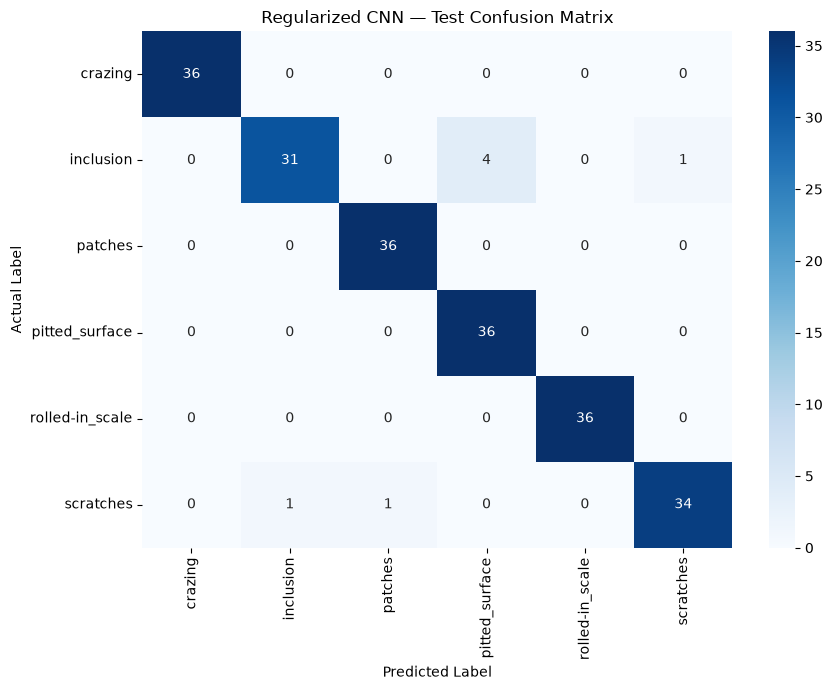

In [139]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Regularized CNN — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [140]:
from pathlib import Path
import torch

final_model_path = Path("models/final_steel_defect_cnn.pth")
final_model_path.parent.mkdir(parents=True, exist_ok=True)

torch.save(
    cnn_regularized_model.state_dict(),
    final_model_path
)

print("Final model saved:", final_model_path.resolve())
print("File size:", round(final_model_path.stat().st_size / (1024 * 1024), 2), "MB")

Final model saved: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook\models\final_steel_defect_cnn.pth
File size: 4.03 MB


In [141]:
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import transforms

class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

inference_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

def predict_defect(image_path):
    image = Image.open(image_path).convert("RGB")
    image_tensor = inference_transform(image).unsqueeze(0)

    cnn_regularized_model.eval()

    with torch.no_grad():
        outputs = cnn_regularized_model(image_tensor)
        probabilities = F.softmax(outputs, dim=1)

        confidence, predicted_class = probabilities.max(dim=1)

    predicted_label = class_names[predicted_class.item()]

    print("Predicted defect:", predicted_label)
    print(f"Confidence: {confidence.item() * 100:.2f}%")

    return predicted_label, confidence.item()

In [142]:
# Select one image from the test dataset
sample_image_path = test_dataset.image_paths[0]

print("Testing image:", sample_image_path)

# Predict its defect class
predicted_label, confidence = predict_defect(sample_image_path)

# Get the actual label
actual_label = class_names[test_dataset.labels[0]]

print("Actual defect:", actual_label)

if predicted_label == actual_label:
    print("Result: CORRECT prediction")
else:
    print("Result: INCORRECT prediction")

Testing image: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw\scratches\scratches_186.jpg
Predicted defect: scratches
Confidence: 100.00%
Actual defect: scratches
Result: CORRECT prediction


In [143]:
import random

sample_indices = random.sample(
    range(len(test_dataset)),
    10
)

correct = 0

for idx in sample_indices:
    image_path = test_dataset.image_paths[idx]
    actual_label = class_names[test_dataset.labels[idx]]

    predicted_label, confidence = predict_defect(image_path)

    if predicted_label == actual_label:
        correct += 1

    print("Actual:", actual_label)
    print("Correct:", predicted_label == actual_label)
    print("-" * 40)

print(f"Accuracy on these 10 images: {correct}/10 ({correct * 10}%)")

Predicted defect: rolled-in_scale
Confidence: 99.74%
Actual: rolled-in_scale
Correct: True
----------------------------------------
Predicted defect: scratches
Confidence: 98.95%
Actual: scratches
Correct: True
----------------------------------------
Predicted defect: scratches
Confidence: 100.00%
Actual: scratches
Correct: True
----------------------------------------
Predicted defect: scratches
Confidence: 100.00%
Actual: scratches
Correct: True
----------------------------------------
Predicted defect: inclusion
Confidence: 98.51%
Actual: inclusion
Correct: True
----------------------------------------
Predicted defect: patches
Confidence: 100.00%
Actual: patches
Correct: True
----------------------------------------
Predicted defect: scratches
Confidence: 64.23%
Actual: scratches
Correct: True
----------------------------------------
Predicted defect: inclusion
Confidence: 89.81%
Actual: inclusion
Correct: True
----------------------------------------
Predicted defect: scratches
C